NAME :  - MUHAMAD ALIF ZULHILMI BIN MOHD ASRI (A208626)
        - MUHAMMAD AIMAN SYAFIQ BIN MOHD HANAFI (A213793)
        - AHMAD DANISH FARHAN BIN AHMAD ZAWANI (A208439)
        - MOKEISH RAJAN BASKARAN (A212069)


Assignment 1: Data Profiling and Exploratory Data Analysis (EDA)

1. Scenario and Dataset Overview

Scenario

This project examines the quality of food delivery data to determine whether it is suitable for further analysis. The dataset contains information about delivery personnel, order conditions, weather, road traffic, and delivery duration. Profiling the data helps identify missing values, unusual values, inconsistent data types, and other potential quality issues before conducting further analysis.

Dataset Overview

- https://www.kaggle.com/datasets/saurabhbadole/zomato-delivery-operations-analytics-dataset

The dataset used in this project is the Zomato Dataset, provided as a CSV file. It contains records related to food delivery, including delivery personnel information, environmental conditions, and order delivery duration.

The purpose of this analysis is to assess the dataset's quality, identify issues that may affect the reliability of the results, and explain appropriate actions for handling those issues.



2. Data Loading and Overview

This section loads the dataset using pandas and examines its basic structure, including the number of rows and columns, column names, data types, and sample records. This initial inspection helps us understand the dataset before identifying data quality issues.


In [3]:

%pip install pandas numpy matplotlib seaborn


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 39.4 MB/s  0:00:006m0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.7/16.7 MB 39.2 MB/s  0:00:006m0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.0/11.0 MB 38.8 MB/s  0:00:006m0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 37.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 27.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.1/7.1 MB 37.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10/10 [seaborn]9/10 [seaborn]ib]

[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [4]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset
df = pd.read_csv("data/Zomato Dataset.csv")

# Display dataset dimensions
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

# Display column names and data types
print("\nDataset information:")
df.info()

# Display the first five records
display(df.head())


Number of rows: 45584
Number of columns: 20

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 45584 entries, 0 to 45583
Data columns (total 20 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   ID                           45584 non-null  str    
 1   Delivery_person_ID           45584 non-null  str    
 2   Delivery_person_Age          43730 non-null  float64
 3   Delivery_person_Ratings      43676 non-null  float64
 4   Restaurant_latitude          45584 non-null  float64
 5   Restaurant_longitude         45584 non-null  float64
 6   Delivery_location_latitude   45584 non-null  float64
 7   Delivery_location_longitude  45584 non-null  float64
 8   Order_Date                   45584 non-null  str    
 9   Time_Orderd                  43853 non-null  str    
 10  Time_Order_picked            45584 non-null  str    
 11  Weather_conditions           44968 non-null  str    
 12  Road_traffic_densit

,ID,Delivery_person_ID,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Order_Date,Time_Orderd,Time_Order_picked,Weather_conditions,Road_traffic_density,Vehicle_condition,Type_of_order,Type_of_vehicle,multiple_deliveries,Festival,City,Time_taken (min)
0,0xcdcd,DEHRES17DEL01,36.0,4.2,30.327968,78.046106,30.397968,78.116106,12-02-2022,21:55,22:10,Fog,Jam,2,Snack,motorcycle,3.0,No,Metropolitian,46
1,0xd987,KOCRES16DEL01,21.0,4.7,10.003064,76.307589,10.043064,76.347589,13-02-2022,14:55,15:05,Stormy,High,1,Meal,motorcycle,1.0,No,Metropolitian,23
2,0x2784,PUNERES13DEL03,23.0,4.7,18.562450,73.916619,18.652450,74.006619,04-03-2022,17:30,17:40,Sandstorms,Medium,1,Drinks,scooter,1.0,No,Metropolitian,21
3,0xc8b6,LUDHRES15DEL02,34.0,4.3,30.899584,75.809346,30.919584,75.829346,13-02-2022,09:20,09:30,Sandstorms,Low,0,Buffet,motorcycle,0.0,No,Metropolitian,20
4,0xdb64,KNPRES14DEL02,24.0,4.7,26.463504,80.372929,26.593504,80.502929,14-02-2022,19:50,20:05,Fog,Jam,1,Snack,scooter,1.0,No,Metropolitian,41



3. Data Profiling and Issue Handling

3.1 Missing Values

Missing values are examined to determine which columns contain incomplete records and how much information is missing. The number and percentage of missing values will be calculated for each column before deciding whether to remove, impute, or flag the affected records.


In [5]:

# Calculate missing values for each column
missing_summary = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage (%)": (df.isnull().sum() / len(df) * 100).round(2)
})

# Display columns with missing values only
missing_summary = missing_summary[
    missing_summary["Missing Count"] > 0
].sort_values(by="Missing Count", ascending=False)

display(missing_summary)


,Missing Count,Missing Percentage (%)
Delivery_person_Ratings,1908,4.19
Delivery_person_Age,1854,4.07
Time_Orderd,1731,3.80
City,1200,2.63
multiple_deliveries,993,2.18
Weather_conditions,616,1.35
Road_traffic_density,601,1.32
Festival,228,0.50


3.1 Missing Value Handling Strategy

Missing values will be handled based on the type and meaning of each variable. Numerical columns, such as delivery personnel age and ratings, will be examined to determine whether imputation is appropriate. Missing categorical values may be labelled as "Unknown" when retaining the records is necessary. Missing order times will be investigated before deciding how to handle them, as replacing them with estimated times may introduce inaccurate information. The original dataset will be preserved for comparison.



In [6]:

# Inspect values in columns with missing data
columns_to_check = [
    "Delivery_person_Age",
    "Delivery_person_Ratings",
    "Time_Orderd",
    "City",
    "multiple_deliveries",
    "Weather_conditions",
    "Road_traffic_density",
    "Festival"
]

for col in columns_to_check:
    print(f"\n--- {col} ---")
    print("Missing values:", df[col].isnull().sum())
    print("Unique values:", df[col].dropna().unique()[:10])



--- Delivery_person_Age ---
Missing values: 1854
Unique values: [36. 21. 23. 34. 24. 29. 35. 33. 25. 31.]

--- Delivery_person_Ratings ---
Missing values: 1908
Unique values: [4.2 4.7 4.3 4.5 4.  4.9 4.1 5.  4.8 3.5]

--- Time_Orderd ---
Missing values: 1731
Unique values: <StringArray>
['21:55', '14:55', '17:30', '09:20', '19:50', '20:25', '20:30', '20:40',
 '21:15', '20:20']
Length: 10, dtype: str

--- City ---
Missing values: 1200
Unique values: <StringArray>
['Metropolitian', 'Urban', 'Semi-Urban']
Length: 3, dtype: str

--- multiple_deliveries ---
Missing values: 993
Unique values: [3. 1. 0. 2.]

--- Weather_conditions ---
Missing values: 616
Unique values: <StringArray>
['Fog', 'Stormy', 'Sandstorms', 'Windy', 'Cloudy', 'Sunny']
Length: 6, dtype: str

--- Road_traffic_density ---
Missing values: 601
Unique values: <StringArray>
['Jam', 'High', 'Medium', 'Low']
Length: 4, dtype: str

--- Festival ---
Missing values: 228
Unique values: <StringArray>
['No', 'Yes']
Length: 2, dtype:


3.2 Outlier Detection Using the IQR Method

The Interquartile Range (IQR) method will be used to identify potential outliers in numerical columns. Values below the lower bound or above the upper bound will be flagged for further investigation. Potential outliers will not be removed automatically because unusual values may represent valid delivery conditions.


In [7]:

# Detect potential outliers using the IQR method
numeric_columns = [
    "Delivery_person_Age",
    "Delivery_person_Ratings",
    "multiple_deliveries",
    "Time_taken (min)"
]

outlier_results = []

for col in numeric_columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)][col]

    outlier_results.append({
        "Column": col,
        "Lower Bound": round(lower_bound, 2),
        "Upper Bound": round(upper_bound, 2),
        "Potential Outliers": len(outliers)
    })

outlier_summary = pd.DataFrame(outlier_results)
display(outlier_summary)


,Column,Lower Bound,Upper Bound,Potential Outliers
0,Delivery_person_Age,10.0,50.0,0
1,Delivery_person_Ratings,3.9,5.5,1223
2,multiple_deliveries,-1.5,2.5,361
3,Time_taken (min),-0.5,51.5,270



Diagnostic Chart: Boxplots of Numerical Variables

Boxplots are used to visualise the distribution and potential outliers identified by the IQR method. The plots help compare unusual values across delivery personnel ratings, multiple deliveries, and delivery duration. Flagged observations will be investigated before deciding whether to retain or correct them.


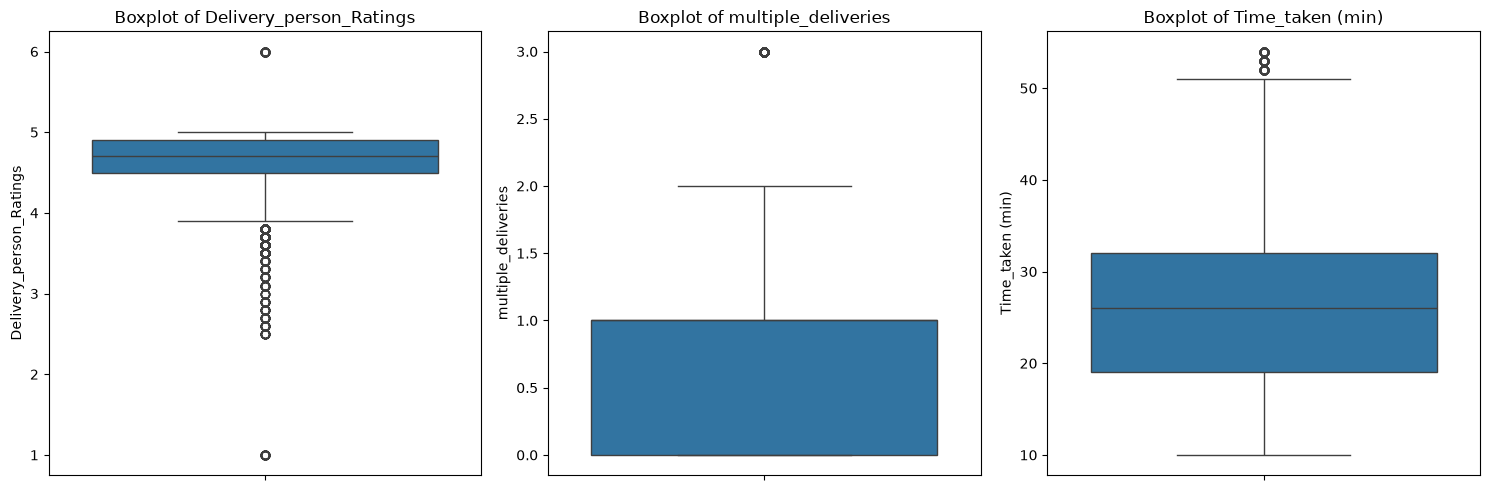

In [8]:

# Visualise potential outliers using boxplots
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

boxplot_columns = [
    "Delivery_person_Ratings",
    "multiple_deliveries",
    "Time_taken (min)"
]

for ax, col in zip(axes, boxplot_columns):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title(f"Boxplot of {col}")
    ax.set_ylabel(col)

plt.tight_layout()
plt.show()


Outlier Handling and Justification

The IQR method was used to identify potential outliers, and boxplots were used to visualise their distributions. The detected values will not be removed automatically because statistical outliers are not necessarily invalid data.

- Delivery_person_Age: No potential outliers were detected using the IQR method. Therefore, no outlier treatment is required based on this test.
- Delivery_person_Ratings: The IQR method identified 1,223 potential outliers. These values will be investigated against the expected rating range of 1 to 5. Ratings within the valid range will be retained because they may represent genuine low ratings, while values outside the valid range will be treated as invalid and investigated separately.
- multiple_deliveries: The IQR method identified 361 potential outliers. These values will be retained if they are valid delivery counts because uncommon numbers of simultaneous deliveries may occur in practice. Values will only be corrected or removed if they are confirmed to be invalid.
- Time_taken (min): The IQR method identified 270 potential outliers. These values will be retained unless further investigation shows that they are invalid, since longer delivery times may result from traffic, weather, or other delivery conditions.

No values are capped or removed solely because they fall outside the IQR bounds. This approach avoids losing potentially valid information and ensures that any data correction is supported by evidence.



3.3 Other Data Quality Issues

This section examines duplicate records, invalid values, and data types that may affect the reliability of the analysis. Each issue will be investigated before deciding whether any correction or removal is necessary.


In [9]:

# 1. Check duplicate rows
print("Duplicate rows:", df.duplicated().sum())

# 2. Check duplicate IDs
print("Duplicate IDs:", df["ID"].duplicated().sum())

# 3. Check ratings outside the expected range (1 to 5)
invalid_ratings = df[
    (df["Delivery_person_Ratings"] < 1) |
    (df["Delivery_person_Ratings"] > 5)
]

print("Ratings outside 1-5:", len(invalid_ratings))
display(invalid_ratings[["ID", "Delivery_person_Ratings"]].head(10))

# 4. Inspect data types
print("\nData types:")
display(df.dtypes.to_frame(name="Data Type"))


Duplicate rows: 0
Duplicate IDs: 0
Ratings outside 1-5: 53


,ID,Delivery_person_Ratings
3577,0x46d,6.0
4705,0x493,6.0
5160,0x4f2,6.0
5353,0x430,6.0
5642,0xbef1,6.0
6385,0x427,6.0
7022,0x3eb,6.0
7672,0xd42,6.0
9490,0x3f0,6.0
9526,0x3ef,6.0



Data types:


,Data Type
ID,str
Delivery_person_ID,str
Delivery_person_Age,float64
Delivery_person_Ratings,float64
Restaurant_latitude,float64
Restaurant_longitude,float64
Delivery_location_latitude,float64
Delivery_location_longitude,float64
Order_Date,str
Time_Orderd,str


In [10]:

# Inspect date and time formats
date_time_columns = [
    "Order_Date",
    "Time_Orderd",
    "Time_Order_picked"
]

for col in date_time_columns:
    print(f"\n--- {col} ---")
    print("Unique sample values:")
    print(df[col].dropna().unique()[:15])
    print("Missing values:", df[col].isnull().sum())



--- Order_Date ---
Unique sample values:
<StringArray>
['12-02-2022', '13-02-2022', '04-03-2022', '14-02-2022', '02-04-2022',
 '01-03-2022', '16-03-2022', '20-03-2022', '15-02-2022', '10-03-2022',
 '11-03-2022', '27-03-2022', '26-03-2022', '05-04-2022', '12-03-2022']
Length: 15, dtype: str
Missing values: 0

--- Time_Orderd ---
Unique sample values:
<StringArray>
['21:55', '14:55', '17:30', '09:20', '19:50', '20:25', '20:30', '20:40',
 '21:15', '20:20', '22:30', '08:15', '19:30', '12:25', '18:35']
Length: 15, dtype: str
Missing values: 1731

--- Time_Order_picked ---
Unique sample values:
<StringArray>
['22:10', '15:05', '17:40', '09:30', '20:05', '20:35', '15:10', '20:40',
 '20:50', '21:30', '20:25', '22:45', '08:30', '19:45', '12:30']
Length: 15, dtype: str
Missing values: 0


Findings and Handling Decisions

- Duplicate records: No fully duplicated rows were found. No rows will be removed for duplication because the initial check found none.
- Duplicate IDs: No duplicate values were found in the `ID` column. Therefore, no ID-based duplicate removal is required based on this check.
- Invalid ratings: A total of 53 records have ratings of 6.0, which exceeds the expected rating range of 1 to 5. These values will be treated as invalid and converted to missing values rather than assigning an arbitrary replacement rating. This preserves the records while preventing invalid ratings from affecting the analysis.
- Data types: The order date and time columns are stored as strings. Their formats will be inspected before conversion to appropriate date and time types. Conversion will only be performed after checking for inconsistent or invalid values.

4. Diagnostic Chart 2: Boxplots of Numerical Variables

The boxplots show the distribution of `Delivery_person_Ratings`, `multiple_deliveries`, and `Time_taken (min)`. Points beyond the whiskers indicate potential outliers based on the distributions of these variables. However, these observations are not automatically considered errors because unusual ratings, delivery counts, or delivery durations may be valid. Further checks against the expected values and meaning of each variable are needed before deciding whether any observations should be corrected or removed.

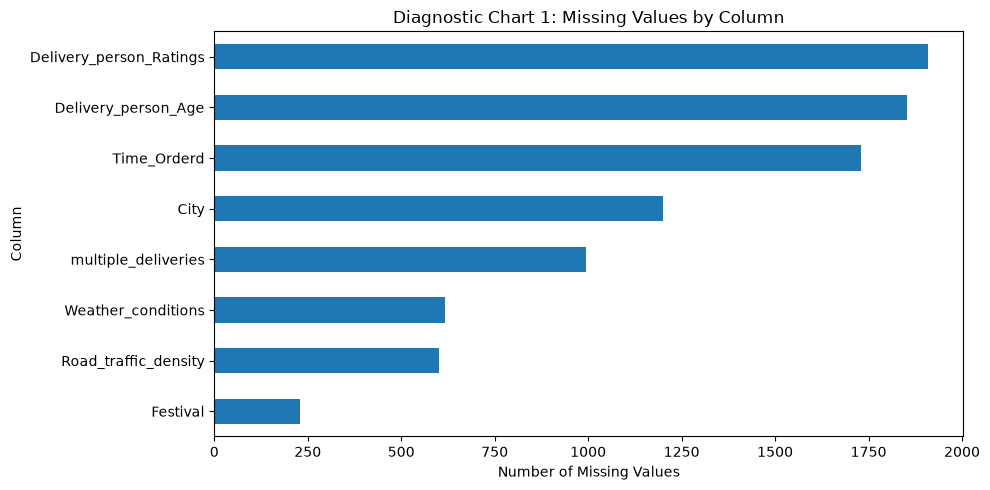

In [12]:
# Chart 1: Missing Values by Column

plt.figure(figsize=(10, 5))

missing_summary["Missing Count"].sort_values().plot(
    kind="barh"
)

plt.title("Diagnostic Chart 1: Missing Values by Column")
plt.xlabel("Number of Missing Values")
plt.ylabel("Column")
plt.tight_layout()
plt.show()

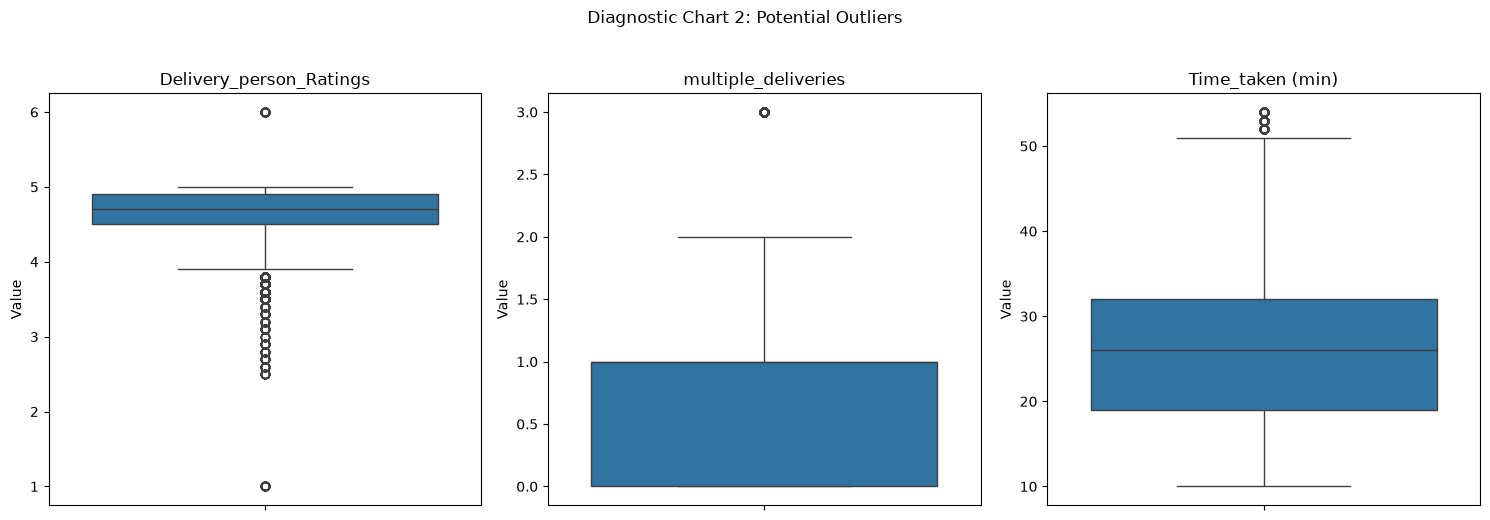

In [13]:
# Chart 2: Boxplots of Numerical Variables

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

boxplot_columns = [
    "Delivery_person_Ratings",
    "multiple_deliveries",
    "Time_taken (min)"
]

for ax, col in zip(axes, boxplot_columns):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title(col)
    ax.set_ylabel("Value")

plt.suptitle("Diagnostic Chart 2: Potential Outliers", y=1.03)
plt.tight_layout()
plt.show()

5. PII and Bias Risks

In [14]:
# Check the distribution of selected categorical variables

categorical_columns = [
    "City",
    "Weather_conditions",
    "Road_traffic_density",
    "Type_of_vehicle"
]

for col in categorical_columns:
    print(f"\nDistribution of {col}:")
    display(df[col].value_counts(dropna=False))


Distribution of City:


City
Metropolitian    34087
Urban            10133
NaN               1200
Semi-Urban         164
Name: count, dtype: int64


Distribution of Weather_conditions:


Weather_conditions
Fog           7653
Stormy        7584
Cloudy        7533
Sandstorms    7494
Windy         7422
Sunny         7282
NaN            616
Name: count, dtype: int64


Distribution of Road_traffic_density:


Road_traffic_density
Low       15476
Jam       14139
Medium    10945
High       4423
NaN         601
Name: count, dtype: int64


Distribution of Type_of_vehicle:


Type_of_vehicle
motorcycle          26429
scooter             15273
electric_scooter     3814
bicycle                68
Name: count, dtype: int64

Potential Bias and Unbalanced Groups

The category distribution shows that some groups are represented much more frequently than others. For example, the `City` column contains 34,887 records classified as `Metropolitian`, compared with only 164 records for `Semi-Urban`. Similarly, `motorcycle` accounts for 26,429 records in the `Type_of_vehicle` column, while `bicycle` accounts for only 68 records.

These differences indicate that the dataset has an uneven distribution across certain categories. Consequently, analysis based on this dataset may reflect the more frequently represented groups and may not accurately describe less frequently represented groups. However, an uneven distribution alone does not prove that the dataset is biased, as the actual distribution of food delivery activities is not known.

To address this limitation, category distributions should be considered when interpreting the results. Where relevant, comparisons can be made separately for different categories, and conclusions about less represented groups should be made cautiously. Missing values in categorical variables should also be considered because they may affect the completeness of the analysis.

6. Conclusion

The Zomato dataset is suitable for the selected scenario of food delivery data profiling because it contains information about delivery personnel, order conditions, weather, traffic density, vehicle conditions, and delivery duration. The profiling process identified several data quality issues, including missing values in eight columns, potential outliers in numerical variables, and 53 invalid delivery ratings outside the expected range of 1 to 5. Duplicate checks also confirmed that no fully duplicated rows or duplicate IDs were found. These findings show why data profiling is necessary before conducting further analysis.

However, some limitations remain. Missing values may affect the reliability of analysis involving ratings, delivery times, and delivery conditions. The uneven distribution of categories, particularly in `City` and `Type_of_vehicle`, may limit comparisons involving less represented groups. In addition, the reasons behind missing values and unusual observations cannot always be determined from the dataset alone. Although invalid ratings and the date data type have been addressed in a separate copy of the dataset, further validation may be required before using the data for more detailed analysis. Overall, the dataset is suitable for the profiling scenario, but its quality limitations should be considered when interpreting any future findings.